In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tabulate import tabulate

In [2]:
data = pd.read_csv('../Dataset Creation/building_mold_risk_5min_1year.csv')

In [3]:
# Display dataset overview
print("Dataset Overview:")
print(tabulate(data.head(), headers="keys", tablefmt="pretty"))

Dataset Overview:
+---+------------+---------------------+-------------------+--------------------+--------------------+--------------------+-----------+
|   |    Date    |      Timestamp      |     Humidity      |    Temperature     |  Light_Intensity   |      Pressure      | Mold_Risk |
+---+------------+---------------------+-------------------+--------------------+--------------------+--------------------+-----------+
| 0 | 2023-01-01 | 2023-01-01 00:00:00 | 52.24505695438245 | 14.570697475053723 | 6.8170151388436615 | 1007.7673625891098 |    Low    |
| 1 | 2023-01-01 | 2023-01-01 00:05:00 | 49.70752286685369 | 19.60825307021918  | 15.293581813641534 | 1011.3497840331516 |    Low    |
| 2 | 2023-01-01 | 2023-01-01 00:10:00 | 52.85847227892171 | 16.899815756209787 | 13.86096472274046  | 1008.2605678805758 |    Low    |
| 3 | 2023-01-01 | 2023-01-01 00:15:00 | 56.37173053558358 | 16.479007833684353 | 10.968900816142227 | 1010.2765405123536 |    Low    |
| 4 | 2023-01-01 | 2023-01-01 

In [4]:
print("\nDataset Info:")
print(data.info())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date             210528 non-null  object 
 1   Timestamp        210528 non-null  object 
 2   Humidity         210528 non-null  float64
 3   Temperature      210528 non-null  float64
 4   Light_Intensity  210528 non-null  float64
 5   Pressure         210528 non-null  float64
 6   Mold_Risk        210528 non-null  object 
dtypes: float64(4), object(3)
memory usage: 11.2+ MB
None


In [5]:
# Display summary statistics
print("\nSummary Statistics:")
summary_stats = data.describe()
print(tabulate(summary_stats, headers="keys", tablefmt="pretty"))


Summary Statistics:
+-------+--------------------+--------------------+--------------------+--------------------+
|       |      Humidity      |    Temperature     |  Light_Intensity   |      Pressure      |
+-------+--------------------+--------------------+--------------------+--------------------+
| count |      210528.0      |      210528.0      |      210528.0      |      210528.0      |
| mean  | 60.006244819245175 | 21.998079871546018 | 283.8658200794276  | 1012.9922009773896 |
|  std  | 13.341342823330729 | 6.816911854574988  | 289.8862588760458  | 7.644548204322292  |
|  min  |        30.0        |        5.0         |        0.0         | 993.0397726312872  |
|  25%  | 50.09597304632773  | 17.115666069197786 | 10.352908198303501 | 1006.4352155306599 |
|  50%  | 60.00325221154627  |  21.9626875554737  | 237.47822295707812 | 1013.0109847440425 |
|  75%  | 69.89900856251816  | 26.90958280085176  | 542.9696479141505  | 1019.5428828602271 |
|  max  | 98.97502977912558  |        4

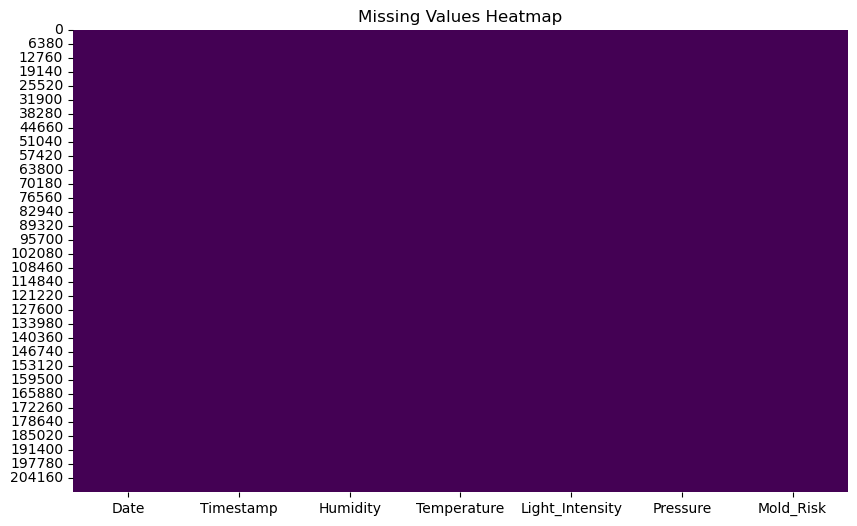

In [6]:
# Visualize missing values
plt.figure(figsize=(10, 6))
sns.heatmap(data.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

In [7]:
print("\nDuplicate Rows:", data.duplicated().sum())
data = data.drop_duplicates()


Duplicate Rows: 0


In [8]:
for col in data.select_dtypes(include=[np.number]).columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data = data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]

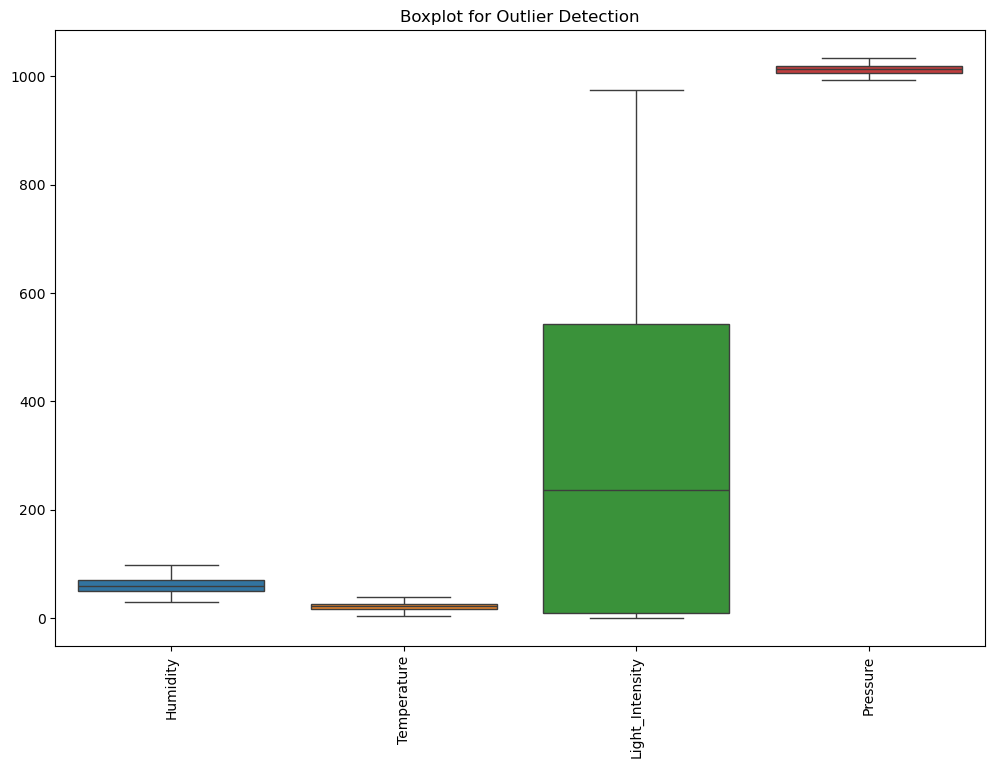

In [9]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=data)
plt.title("Boxplot for Outlier Detection")
plt.xticks(rotation=90)
plt.show()

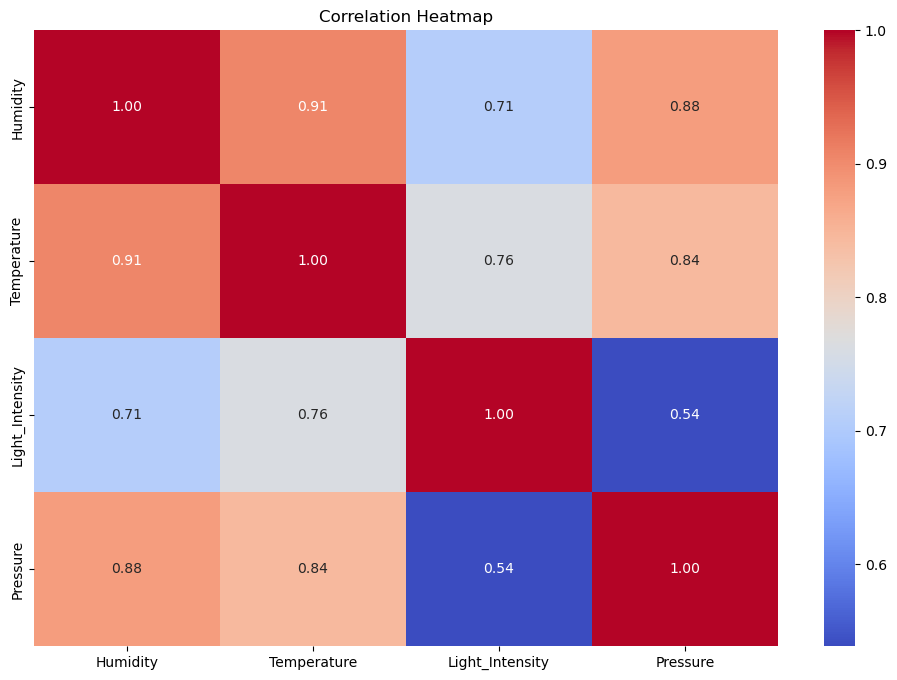

In [10]:
# Filter numeric columns
numeric_data = data.select_dtypes(include=[float, int])

# Check if there are enough numeric columns
if numeric_data.shape[1] >= 2:
    # Compute correlation and plot heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.show()
else:
    print("Not enough numeric data for correlation heatmap.")